# Local validation of the Databricks export

Runs the automated checks on every series in `input_output/output_databricks/` — the raw
hourly copy pulled from Databricks via git — and folds new data into the validation store.

The data lives in three separate layers, and nothing here ever writes to layer 1:

| Layer | Folder | Git | Role |
|---|---|---|---|
| 1. Source copy | `input_output/output_databricks/` | tracked | exact copy of Databricks; **read-only** (overwritten by each export) |
| 2. Derived | `output_data/validated/`, `output_data/validation_summary.csv` | ignored | automated flags; disposable, rebuilt here |
| 3. Validation store | `input_output/output_repository/<filename>.csv` | tracked | human review decisions; **merged into, never replaced** |

**Flag layers** run in order on `head`. Each stores the original value of what it flags in
its own column and sets `head` to NaN, so the next layer only sees what is left:

| | Check | Default |
|---|---|---|
| `v1` | Out of bounds: below the filter bottom, or above the top of the well | `eind_filter` / `bovenkant_peilbuis` |
| `v2` | Unrealistic step change between two hours | up > +0.30 m, down < −0.05 m |
| `v3` | At the filter bottom: within 0.15 m of `eind_filter` (inclusive) | −4.10 → −3.95 and −4.05 flagged, −3.92 not |
| `v4` | Statistical outlier (Tukey / IQR) | outside Q1 − 1.5·IQR .. Q3 + 1.5·IQR |

**Autoflag rules**, on the raw value (they act on the review store):

| | Rule | Default |
|---|---|---|
| `rule_a` | Drop ≥ 0.10 m in one hourly step (contiguous hours) | report-only |
| `rule_b` | Value ≤ filter bottom + 0.10 m | applied (`afgekeurd = 1` in the store) |

**Manual review** always overrides these: `checks.apply_autoflags()` never touches a row a
human marked `gecontroleerd`.

Thresholds and paths come from `config/settings.yaml`.

In [1]:
import sys
from pathlib import Path

# Make the repo importable wherever Jupyter was started (repo root or local_validation/).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "local_validation").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from local_validation import checks, data_io

settings = data_io.load_settings()
TH = data_io.thresholds(settings)
TH

Thresholds(v2_max_up=0.3, v2_max_down=-0.05, v3_band=0.15, v3_min_run=1, v4_iqr_factor=1.5, rule_a_drop=0.1, rule_b_margin=0.1, freq='1h')

## The export

In [2]:
meta = data_io.load_object_data(settings)
print(f"{len(meta)} series")
print(meta["vendor"].value_counts().to_string())
if "matched" in meta:
    print()
    print(meta["matched"].value_counts().to_string())
print()
print(f"eind_filter known:  {meta['eind_filter'].notna().sum()}  (v1 lower bound, v3, rule B)")
print(f"top of well known:  {meta['bovenkant_peilbuis'].notna().sum()}  (v1 upper bound)")

677 series
vendor
wiertsema    342
fugro        335

matched
matched                          386
no match found in cs_objecten    291

eind_filter known:  423  (v1 lower bound, v3, rule B)
top of well known:  386  (v1 upper bound)


## One series

Pick any `filename` from `object_data.csv`. The plot shows the raw series in grey and each
flagged hour in the colour of the layer that took it.

In [3]:
FILENAME = meta.loc[meta["eind_filter"].notna(), "filename"].iloc[0]   # or e.g. "HB15-PB1__b4f0f98e8948"

row = next(meta[meta["filename"] == FILENAME].itertuples(index=False))
result = data_io.validate_row(settings, row, TH)
pd.Series(data_io.summarize(row, result))

filename                                          HB15-PB1__b4f0f98e8948
meetreeks_id           b4f0f98e89488ce5b68d1d8d256e6c1d7725523e8017b6...
vendor                                                             fugro
filter_bottom                                                       -4.2
eind_filter                                                         -4.2
top_of_well                                                         None
n_hours                                                            20389
n_v1                                                                   2
n_v2                                                                 349
n_v3                                                                   0
n_v4                                                                   0
n_rule_a                                                              30
n_rule_b                                                               2
n_valid_after_flags                                

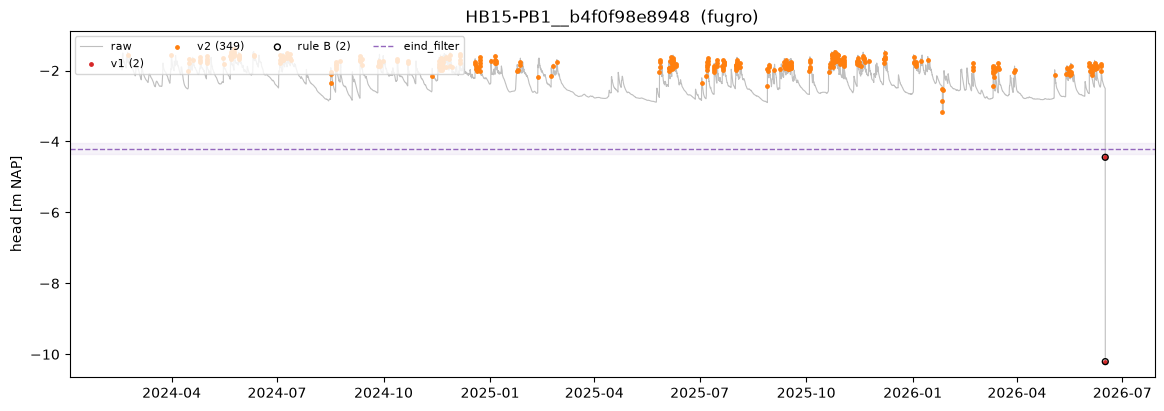

In [4]:
def plot_result(result, row, ax=None):
    ax = ax or plt.subplots(figsize=(14, 4.5))[1]
    ax.plot(result.index, result["raw_head"], color="0.75", lw=0.8, label="raw")
    colours = {"v1": "tab:red", "v2": "tab:orange", "v3": "tab:purple", "v4": "tab:blue"}
    for col, colour in colours.items():
        hit = result[col].dropna()
        if len(hit):
            ax.scatter(hit.index, hit, s=6, color=colour, label=f"{col} ({len(hit)})", zorder=3)
    rb = result.loc[result["rule_b"], "raw_head"]
    if len(rb):
        ax.scatter(rb.index, rb, s=18, facecolors="none", edgecolors="black",
                   label=f"rule B ({len(rb)})", zorder=4)
    eind = checks.as_float(row.eind_filter)
    if eind is not None:
        ax.axhline(eind, color="tab:purple", ls="--", lw=1, label="eind_filter")
        ax.axhspan(eind - TH.v3_band, eind + TH.v3_band, color="tab:purple", alpha=0.08)
    top = checks.as_float(row.bovenkant_peilbuis)
    if top is not None:
        ax.axhline(top, color="tab:red", ls=":", lw=1, label="top of well")
    ax.set_title(f"{row.filename}  ({row.vendor})")
    ax.set_ylabel("head [m NAP]")
    ax.legend(loc="upper left", fontsize=8, ncol=4)
    return ax


plot_result(result, row);

## All series

Validates everything and writes `output_data/validated/` + `output_data/validation_summary.csv`.
About 30 s for ~700 series.

In [5]:
summary = data_io.validate_all(settings, TH)
totals = summary[[c for c in summary if c.startswith("n_")]].sum()
pd.DataFrame({"hours": totals, "pct": (100 * totals / totals["n_hours"]).round(2)})

,hours,pct
n_hours,6170898,100.00
n_v1,82857,1.34
n_v2,10986,0.18
n_v3,53934,0.87
n_v4,119186,1.93
n_rule_a,3111,0.05
n_rule_b,93938,1.52
n_valid_after_flags,5903935,95.67


In [6]:
by_vendor = summary.groupby("vendor")[[c for c in summary if c.startswith("n_")]].sum()
by_vendor["pct_kept"] = (100 * by_vendor["n_valid_after_flags"] / by_vendor["n_hours"]).round(1)
by_vendor

,n_hours,n_v1,n_v2,n_v3,n_v4,n_rule_a,n_rule_b,n_valid_after_flags,pct_kept
vendor,,,,,,,,,
fugro,2165032,61740,8267,40350,57449,2461,70938,1997226,92.2
wiertsema,4005866,21117,2719,13584,61737,650,23000,3906709,97.5


Series that lose the largest share of their hours — the first ones to look at in review.

In [7]:
flag_cols = [f"n_{c}" for c in checks.FLAG_COLUMNS]
worst = summary.assign(pct_flagged=(100 * (1 - summary["n_valid_after_flags"] / summary["n_hours"])).round(1))
worst.sort_values("pct_flagged", ascending=False)[["filename", "vendor", "n_hours", *flag_cols,
                                                    "n_rule_b", "pct_flagged"]].head(15)

,filename,vendor,n_hours,n_v1,n_v2,n_v3,n_v4,n_rule_b,pct_flagged
22,B13-PB2__cbb53ccf80c2,fugro,15852,15852,0,0,0,6,100.0
367,MSLV5_k75120,wiertsema,8054,8054,0,0,0,8054,100.0
461,KELLER_00205132,wiertsema,8722,8722,0,0,0,0,100.0
124,B109-PB2__cee107f72683,fugro,845,845,0,0,0,845,100.0
117,B101-PB2,fugro,4684,4684,0,0,0,4684,100.0
120,B104-PB2__4561eb124393,fugro,4685,4685,0,0,0,4685,100.0
74,HB31-PB1,fugro,6087,6018,0,0,0,6018,98.9
28,B16-PB2,fugro,11346,9709,0,1190,7,10759,96.1
380,MSLV8_o54178__463e6832da8e,wiertsema,16044,3716,8,10855,80,13671,91.4
132,HB116-PB1,fugro,4697,172,2,4078,0,4031,90.5


## Sync the validation store (layer 3)

After a new export, fold the new source data into the existing stores. The merge keeps every
reviewed row as it is (value, verdict and note), refreshes unreviewed values, appends new hours
as unreviewed, and applies rule B to unreviewed rows (`afgekeurd = 1`, note `auto: rule B`).

Stores are created lazily, when a series is first saved in the review app. Set
`CREATE_MISSING = True` to create one for every series now; that adds roughly 200 MB to git.
`DRY_RUN = True` only reports what would change.

In [8]:
from local_validation import stores

CREATE_MISSING = False
DRY_RUN = False

report = stores.sync_stores(settings, TH, create_missing=CREATE_MISSING, dry_run=DRY_RUN)
if report.empty:
    print("No validation stores yet - they appear once a series is saved in the review app.")
else:
    print(f"{len(report)} stores | written: {int(report['written'].sum())} | "
          f"new hours: {int(report['new_rows'].sum())} | auto-rejected: {int(report['autoflagged'].sum())}")
report[report["written"] | report["created"]]

5 stores | written: 5 | new hours: 2379 | auto-rejected: 0


,filename,created,new_rows,autoflagged,written
0,MSLV5_jc4354,False,459,0,True
1,MSLV8_o74679,False,480,0,True
2,MSLV8_o54154,False,480,0,True
3,MSLV8_o54294,False,480,0,True
4,MSLV8_o54166,False,480,0,True


## Next: manual review

```
streamlit run streamlit_app.py --server.port 8502
```

The **Map** page (landing) shows every series with location metadata. **Review** walks one
series point by point and writes its verdicts to `input_output/output_repository/`. **Overview**
tracks progress. Then commit and push only `input_output/output_repository/`, pull in
Databricks, and run `03_validated_to_delta`.